# UTS Praktikum Visi Komputer
## Tema 4: Pencarian Sampul Buku di Rak

| Keterangan | Detail |
|---|---|
| **Kelompok** | 04 |
| **Tema** | 4 – Pencarian Sampul Buku di Rak |

### Anggota Kelompok

| No | Nama | NIM | 
|---|---|---|
| 1 | Muhammad Al-Hadziq Tarmizi | 21087010022 | 
| 2 | M.Anis Fathin| 2408107010045 | 
| 3 | Khalish Aufa | 2408107010068 | 


---

### Deskripsi Tugas

Diberikan foto **template** sampul buku, program menemukan dan menandai buku tersebut pada foto rak/meja yang berisi banyak buku. Jika buku tidak ditemukan, program menyatakan **"Tidak Ditemukan"**.

### Materi Wajib
- **Prak 3**: `cv2.resize` untuk menyesuaikan ukuran citra
- **Prak 5**: ORB / SIFT untuk deteksi keypoint dan deskriptor
- **Prak 5**: `BFMatcher` + ratio test (Lowe's) untuk mencocokkan fitur
- **Prak 5**: `findHomography` (RANSAC) + `perspectiveTransform` untuk menggambar kotak lokasi buku

---
## 1. Import Library dan Fungsi Bantu

Library yang digunakan hanya **opencv-python**, **numpy**, dan **matplotlib** sesuai aturan UTS.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import csv
import time

print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version: {np.__version__}")

OpenCV version: 5.0.0
NumPy version: 2.5.3


### 1.1 Fungsi Bantu Preprocessing (Prak 3)

Fungsi `resize_image()` meng-resize citra agar sisi terpanjang menjadi `max_side` piksel.  
Ini mengikuti ketentuan UTS agar proses tidak lambat (sisi terpanjang 800–1200 piksel).

In [2]:
def resize_image(img, max_side=1000):
    """
    Resize citra agar sisi terpanjang = max_side piksel.
    Menjaga rasio aspek.
    
    Materi: cv2.resize (Prak 3)
    
    Parameter:
    ----------
    img : numpy.ndarray
        Citra input (BGR)
    max_side : int
        Ukuran sisi terpanjang target (default 1000)
    
    Returns:
    --------
    numpy.ndarray
        Citra yang sudah di-resize
    """
    h, w = img.shape[:2]
    if max(h, w) <= max_side:
        return img.copy()
    
    scale = max_side / max(h, w)
    new_w = int(w * scale)
    new_h = int(h * scale)
    
    # Menggunakan INTER_AREA untuk downscaling (menghasilkan kualitas lebih baik)
    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    return resized


def load_image(path, max_side=1000):
    """
    Membaca citra dari file dan langsung di-resize.
    
    Materi: cv2.imread (Prak 2), cv2.resize (Prak 3)
    """
    img = cv2.imread(path)
    if img is None:
        print(f"[ERROR] Gagal membaca: {path}")
        return None
    return resize_image(img, max_side)

### 1.2 Fungsi Bantu Konversi Warna (Prak 3)

Konversi BGR → Grayscale diperlukan sebelum deteksi fitur.

In [3]:
def to_grayscale(img):
    """
    Konversi citra BGR ke Grayscale.
    
    Materi: cv2.cvtColor (Prak 3)
    """
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

### 1.3 Fungsi Deteksi Fitur (Prak 5)

Dua detektor fitur diimplementasikan:
- **ORB** (Oriented FAST and Rotated BRIEF): Cepat, gratis, cocok untuk real-time.  
  Menggunakan deskriptor biner sehingga matching dengan Hamming distance.
- **SIFT** (Scale-Invariant Feature Transform): Lebih akurat, invarian terhadap skala dan rotasi.  
  Menggunakan deskriptor float sehingga matching dengan L2 norm.

Parameter `nfeatures` pada ORB diatur 5000 (default 500) agar keypoint cukup banyak untuk matching.

In [4]:
def detect_features(gray, method='ORB', nfeatures=5000):
    """
    Deteksi keypoint dan hitung deskriptor.
    
    Materi: cv2.ORB_create, cv2.SIFT_create (Prak 5)
    
    Parameter:
    ----------
    gray : numpy.ndarray
        Citra grayscale
    method : str
        'ORB' atau 'SIFT'
    nfeatures : int
        Jumlah fitur maksimal (berlaku untuk ORB dan SIFT)
    
    Returns:
    --------
    keypoints : list of cv2.KeyPoint
    descriptors : numpy.ndarray
    """
    if method == 'ORB':
        detector = cv2.ORB_create(nfeatures=nfeatures)
    elif method == 'SIFT':
        detector = cv2.SIFT_create(nfeatures=nfeatures)
    else:
        raise ValueError(f"Method '{method}' tidak dikenal. Gunakan 'ORB' atau 'SIFT'.")
    
    keypoints, descriptors = detector.detectAndCompute(gray, None)
    return keypoints, descriptors

### 1.4 Fungsi Feature Matching (Prak 5)

Menggunakan **BFMatcher** (Brute-Force Matcher) dengan **Lowe's Ratio Test**:  
- Untuk setiap deskriptor template, cari 2 kandidat terdekat di citra adegan (`knnMatch(k=2)`).  
- Match dianggap "good" jika jarak terbaik ≤ `ratio × jarak kedua terbaik`.  
- Ratio test menyaring match yang ambigu (nilai kecil = lebih ketat).

Norm yang digunakan:
- **NORM_HAMMING** untuk ORB (deskriptor biner)
- **NORM_L2** untuk SIFT (deskriptor float)

In [5]:
def match_features(desc_template, desc_scene, method='ORB', ratio=0.75):
    """
    Mencocokkan deskriptor template dan scene menggunakan BFMatcher + ratio test.
    
    Materi: cv2.BFMatcher, knnMatch, Lowe's ratio test (Prak 5)
    
    Parameter:
    ----------
    desc_template : numpy.ndarray
        Deskriptor template
    desc_scene : numpy.ndarray
        Deskriptor scene (adegan)
    method : str
        'ORB' (NORM_HAMMING) atau 'SIFT' (NORM_L2)
    ratio : float
        Threshold ratio test Lowe (default 0.75)
    
    Returns:
    --------
    good_matches : list of cv2.DMatch
        Daftar match yang lolos ratio test
    """
    if desc_template is None or desc_scene is None:
        return []
    
    if len(desc_template) < 2 or len(desc_scene) < 2:
        return []
    
    # Pilih norm berdasarkan metode
    if method == 'ORB':
        norm = cv2.NORM_HAMMING
    else:
        norm = cv2.NORM_L2
    
    bf = cv2.BFMatcher(norm, crossCheck=False)
    
    # knnMatch: untuk setiap deskriptor, cari k=2 kandidat terdekat
    matches = bf.knnMatch(desc_template, desc_scene, k=2)
    
    # Ratio test (Lowe's): hanya simpan match jika jaraknya signifikan
    # lebih kecil daripada kandidat kedua
    good_matches = []
    for match_pair in matches:
        if len(match_pair) == 2:
            m, n = match_pair
            if m.distance < ratio * n.distance:
                good_matches.append(m)
    
    return good_matches

### 1.5 Fungsi Homography dan Visualisasi (Prak 5)

Jika jumlah good match ≥ `min_match_count` (default 10):
1. Hitung **homography** dari titik-titik match menggunakan `findHomography` dengan metode **RANSAC**.  
   RANSAC robust terhadap outlier (match yang salah).
2. Transformasikan 4 sudut template ke koordinat scene menggunakan `perspectiveTransform`.
3. Gambar poligon 4 sisi (kotak perspektif) pada citra scene.

In [6]:
def find_book_in_scene(kp_template, kp_scene, good_matches, template_shape,
                       min_match_count=10):
    """
    Menghitung homography dan mengembalikan 4 titik sudut buku di scene.
    
    Materi: cv2.findHomography (RANSAC), cv2.perspectiveTransform (Prak 5)
    
    Parameter:
    ----------
    kp_template : list of cv2.KeyPoint
    kp_scene : list of cv2.KeyPoint
    good_matches : list of cv2.DMatch
    template_shape : tuple (h, w)
        Ukuran citra template
    min_match_count : int
        Jumlah minimum good match untuk menghitung homography
    
    Returns:
    --------
    found : bool
        True jika buku ditemukan
    dst_pts : numpy.ndarray atau None
        4 titik sudut buku di scene (jika ditemukan)
    mask : numpy.ndarray atau None
        Mask inlier dari RANSAC
    """
    if len(good_matches) < min_match_count:
        return False, None, None
    
    # Ambil koordinat titik dari keypoint yang cocok
    src_pts = np.float32([kp_template[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    
    # Hitung homography dengan RANSAC
    # ransacReprojThreshold=5.0 adalah toleransi reproyeksi (piksel)
    M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    
    if M is None:
        return False, None, None
    
    # Hitung jumlah inlier
    inlier_count = int(mask.sum()) if mask is not None else 0
    inlier_ratio = inlier_count / len(good_matches) if len(good_matches) > 0 else 0
    
    # Jika inlier terlalu sedikit, homography tidak reliable
    if inlier_count < min_match_count // 2 or inlier_ratio < 0.3:
        return False, None, None
    
    # Definisikan 4 sudut template
    h, w = template_shape[:2]
    corners_template = np.float32([
        [0, 0],
        [w, 0],
        [w, h],
        [0, h]
    ]).reshape(-1, 1, 2)
    
    # Transformasikan sudut template ke koordinat scene
    corners_scene = cv2.perspectiveTransform(corners_template, M)
    
    # Validasi: periksa apakah poligon hasil masuk akal
    # (bukan terlalu kecil, terlalu besar, atau terbalik)
    polygon = corners_scene.reshape(4, 2)
    area = cv2.contourArea(polygon.astype(np.float32))
    if area < 1000 or area > (template_shape[0] * template_shape[1] * 20):
        return False, None, None
    
    # Periksa apakah poligon convex (bentuk wajar)
    if not cv2.isContourConvex(polygon.astype(np.int32)):
        return False, None, None
    
    return True, corners_scene, mask

In [7]:
def draw_result(scene_img, template_name, found, corners=None, 
                num_good_matches=0, color=(0, 255, 0)):
    """
    Menggambar poligon dan teks hasil deteksi pada citra scene.
    
    Materi: cv2.polylines, cv2.putText (Prak 4)
    
    Parameter:
    ----------
    scene_img : numpy.ndarray
        Citra scene (BGR)
    template_name : str
        Nama template buku
    found : bool
    corners : numpy.ndarray atau None
    num_good_matches : int
    color : tuple
        Warna garis (BGR)
    
    Returns:
    --------
    numpy.ndarray
        Citra scene dengan anotasi
    """
    result = scene_img.copy()
    
    if found and corners is not None:
        # Gambar poligon 4 sisi
        pts = np.int32(corners).reshape(-1, 2)
        cv2.polylines(result, [pts], isClosed=True, color=color, thickness=3)
        
        # Tulis label di atas poligon
        top_left = pts[0]
        label = f"DITEMUKAN: {template_name}"
        cv2.putText(result, label, 
                    (top_left[0], top_left[1] - 15),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
        cv2.putText(result, f"Good Matches: {num_good_matches}",
                    (top_left[0], top_left[1] - 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    else:
        # Tidak ditemukan
        label = f"TIDAK DITEMUKAN: {template_name} (matches: {num_good_matches})"
        cv2.putText(result, label,
                    (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
    
    return result

### 1.6 Fungsi Pipeline Utama

Menggabungkan semua tahap menjadi satu fungsi `search_book()` yang menerima path template dan path scene.

In [8]:
def search_book(template_path, scene_path, method='ORB', ratio=0.75, 
                min_match_count=10, nfeatures=5000, max_side=1000,
                verbose=False):
    """
    Pipeline lengkap: mencari buku template di dalam foto adegan.
    
    Tahapan:
    1. Load & resize (Prak 2 & 3)
    2. Convert to grayscale (Prak 3)
    3. Detect keypoints & descriptors (Prak 5)
    4. Match features dengan BFMatcher + ratio test (Prak 5)
    5. Find homography dengan RANSAC (Prak 5)
    6. Draw result (Prak 4)
    
    Returns:
    --------
    dict : hasil lengkap berisi semua informasi deteksi
    """
    start_time = time.time()
    
    # --- Tahap 1: Load & Resize ---
    template_img = load_image(template_path, max_side)
    scene_img = load_image(scene_path, max_side)
    
    if template_img is None or scene_img is None:
        return {'found': False, 'error': 'Gagal membaca citra'}
    
    # --- Tahap 2: Grayscale ---
    gray_template = to_grayscale(template_img)
    gray_scene = to_grayscale(scene_img)
    
    # --- Tahap 3: Deteksi Fitur ---
    kp_t, desc_t = detect_features(gray_template, method, nfeatures)
    kp_s, desc_s = detect_features(gray_scene, method, nfeatures)
    
    # --- Tahap 4: Matching ---
    good_matches = match_features(desc_t, desc_s, method, ratio)
    
    # --- Tahap 5: Homography ---
    found, corners, mask = find_book_in_scene(
        kp_t, kp_s, good_matches, gray_template.shape, min_match_count
    )
    
    elapsed = time.time() - start_time
    
    template_name = os.path.splitext(os.path.basename(template_path))[0]
    
    # --- Tahap 6: Visualisasi ---
    result_img = draw_result(scene_img, template_name, found, corners, len(good_matches))
    
    # Gambar matching untuk visualisasi
    if found and mask is not None:
        matchesMask = mask.ravel().tolist()
    else:
        matchesMask = None
    
    draw_params = dict(
        matchColor=(0, 255, 0),
        singlePointColor=(255, 0, 0),
        matchesMask=matchesMask,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    
    match_img = cv2.drawMatches(
        template_img, kp_t,
        scene_img, kp_s,
        good_matches, None, **draw_params
    )
    
    return {
        'found': found,
        'corners': corners,
        'num_keypoints_template': len(kp_t),
        'num_keypoints_scene': len(kp_s),
        'num_good_matches': len(good_matches),
        'inlier_count': int(mask.sum()) if mask is not None else 0,
        'time_seconds': elapsed,
        'method': method,
        'ratio': ratio,
        'template_img': template_img,
        'scene_img': scene_img,
        'gray_template': gray_template,
        'gray_scene': gray_scene,
        'result_img': result_img,
        'match_img': match_img,
        'template_name': template_name
    }

### 1.7 Fungsi Visualisasi dengan Matplotlib (Prak 2)

Fungsi bantu untuk menampilkan banyak gambar dalam satu figure menggunakan matplotlib.

In [10]:
def show_images(images, titles=None, cols=3, figsize=(18, 6), cmap=None):
    """
    Menampilkan beberapa citra dalam satu figure.
    
    Materi: matplotlib subplot (Prak 2)
    """
    n = len(images)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = axes.flatten()
    
    for i, ax in enumerate(axes):
        if i < n:
            img = images[i]
            if len(img.shape) == 2:
                ax.imshow(img, cmap='gray')
            else:
                ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            if titles and i < len(titles):
                ax.set_title(titles[i], fontsize=10)
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()


def show_single(img, title='', figsize=(10, 8)):
    """
    Menampilkan satu citra.
    """
    plt.figure(figsize=figsize)
    if len(img.shape) == 2:
        plt.imshow(img, cmap='gray')
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=12)
    plt.axis('off')
    plt.show()

---
## 2. Memuat Dataset

### Struktur folder dataset:
```
dataset/
    template/         # Foto sampul buku (5 template)
        buku1.jpg
        buku2.jpg
        ...
    adegan/
        ideal/        # 8 foto adegan ideal
            ideal_01.jpg
            ...
        sudut/        # 6 foto sudut miring
            sudut_01.jpg
            ...
        tertutup/     # 3 foto buku tertutup sebagian
            tertutup_01.jpg
            ...
        tanpa_target/ # 3 foto tanpa buku target
            tanpa_01.jpg
            ...
    ground_truth.csv
```



In [11]:
# ============================================================
# Path dataset 
# ============================================================

DATASET_DIR = 'dataset'
TEMPLATE_DIR = os.path.join(DATASET_DIR, 'template')
SCENE_DIR = os.path.join(DATASET_DIR, 'adegan')
GT_FILE = os.path.join(DATASET_DIR, 'ground_truth.csv')
OUTPUT_DIR = 'output'

# Buat folder output jika belum ada
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# Daftar kondisi adegan
# ============================================================
KONDISI_LIST = ['ideal', 'sudut', 'tertutup', 'tanpa_target']

# ============================================================
# Muat semua path template
# ============================================================
template_files = sorted([
    f for f in os.listdir(TEMPLATE_DIR) 
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

template_paths = {os.path.splitext(f)[0]: os.path.join(TEMPLATE_DIR, f) 
                  for f in template_files}

print(f"Jumlah template buku: {len(template_paths)}")
for name, path in template_paths.items():
    print(f"  - {name}: {path}")

Jumlah template buku: 5
  - buku1: dataset\template\buku1.jpg
  - buku2: dataset\template\buku2.jpg
  - buku3: dataset\template\buku3.jpg
  - buku4: dataset\template\buku4.jpg
  - buku5: dataset\template\buku5.jpg


In [12]:
# ============================================================
# Muat semua path foto adegan per kondisi
# ============================================================
scene_files = {}  # {kondisi: [list of paths]}

for kondisi in KONDISI_LIST:
    kondisi_dir = os.path.join(SCENE_DIR, kondisi)
    if os.path.isdir(kondisi_dir):
        files = sorted([
            f for f in os.listdir(kondisi_dir) 
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        scene_files[kondisi] = [os.path.join(kondisi_dir, f) for f in files]
        print(f"Kondisi '{kondisi}': {len(files)} foto")
    else:
        scene_files[kondisi] = []
        print(f"Kondisi '{kondisi}': folder tidak ditemukan")

total_scenes = sum(len(v) for v in scene_files.values())
print(f"\nTotal foto adegan: {total_scenes}")

Kondisi 'ideal': 8 foto
Kondisi 'sudut': 6 foto
Kondisi 'tertutup': 3 foto
Kondisi 'tanpa_target': 3 foto

Total foto adegan: 20


In [15]:
# ============================================================
# Muat Ground Truth
# ============================================================
# Format ground_truth.csv:
# file,kondisi,buku_target,ditemukan,keterangan
# ideal_01.jpg,ideal,buku1;buku3,ya,"buku1 dan buku3 terlihat jelas"
# tanpa_01.jpg,tanpa_target,,tidak,"tidak ada buku target"


ground_truth = []

if os.path.exists(GT_FILE):
    with open(GT_FILE, 'r', encoding='utf-8') as f:
        reader = csv.DictReader(f)
        for row in reader:
            # Parse buku_target menjadi list
            buku_target = []
            if row.get('buku_target', '').strip():
                buku_target = [b.strip() for b in row['buku_target'].split(';')]
            
            ground_truth.append({
                'file': row['file'].strip(),
                'kondisi': row['kondisi'].strip(),
                'buku_target': buku_target,
                'ditemukan': row.get('ditemukan', '').strip().lower(),
                'keterangan': row.get('keterangan', '').strip()
            })
    
    print(f"Ground truth dimuat: {len(ground_truth)} entri")
    print("\nContoh:")
    for gt in ground_truth[:3]:
        print(f"  {gt['file']} [{gt['kondisi']}]: target={gt['buku_target']}, "
              f"ditemukan={gt['ditemukan']}")
else:
    print(f"[WARNING] File ground truth tidak ditemukan: {GT_FILE}")
    print("Buat file ground_truth.csv dengan format:")
    print("  file,kondisi,buku_target,ditemukan,keterangan")

Ground truth dimuat: 20 entri

Contoh:
  ideal_01.jpg [ideal]: target=['buku1', 'buku3'], ditemukan=ya
  ideal_02.jpg [ideal]: target=['buku2', 'buku4'], ditemukan=ya
  ideal_03.jpg [ideal]: target=['buku1', 'buku2', 'buku5'], ditemukan=ya


### 2.1 Menampilkan Contoh Dataset

Tampilkan semua template dan 1 contoh foto per kondisi adegan.

TEMPLATE BUKU


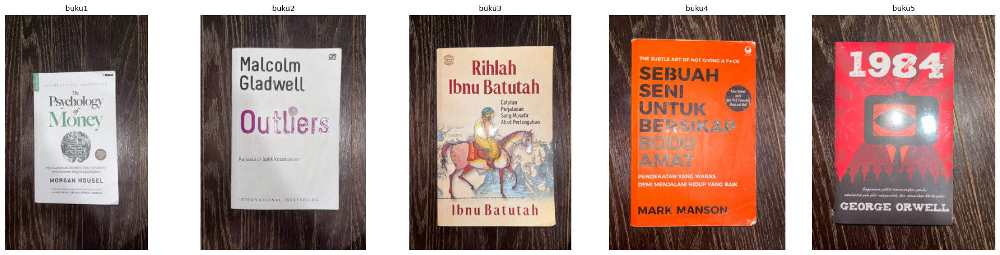

In [16]:
# Tampilkan semua template buku
print("=" * 60)
print("TEMPLATE BUKU")
print("=" * 60)

template_images = []
template_titles = []
for name, path in template_paths.items():
    img = load_image(path, max_side=400)
    if img is not None:
        template_images.append(img)
        template_titles.append(name)

if template_images:
    show_images(template_images, template_titles, 
                cols=min(5, len(template_images)), figsize=(20, 5))

CONTOH FOTO ADEGAN (1 per kondisi)


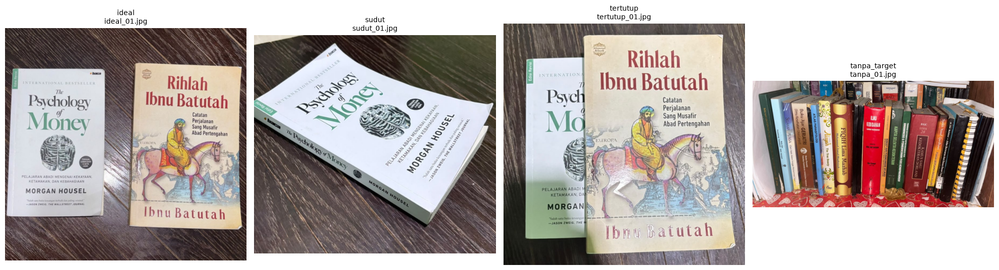

In [17]:
# Tampilkan 1 contoh per kondisi adegan
print("=" * 60)
print("CONTOH FOTO ADEGAN (1 per kondisi)")
print("=" * 60)

sample_images = []
sample_titles = []

for kondisi in KONDISI_LIST:
    if scene_files.get(kondisi):
        path = scene_files[kondisi][0]
        img = load_image(path, max_side=600)
        if img is not None:
            sample_images.append(img)
            sample_titles.append(f"{kondisi}\n{os.path.basename(path)}")

if sample_images:
    show_images(sample_images, sample_titles, 
                cols=min(4, len(sample_images)), figsize=(20, 6))

---
## 3. Pipeline Langkah demi Langkah

Di bagian ini, kita jalankan pipeline pada **satu contoh** dan tampilkan **hasil antara** setiap tahap.

### Alur Pipeline:
```
Template + Scene
      ↓
  Resize (Prak 3)
      ↓
  Grayscale (Prak 3)
      ↓
  Deteksi Keypoint & Deskriptor (Prak 5: ORB/SIFT)
      ↓
  Feature Matching: BFMatcher + Ratio Test (Prak 5)
      ↓
  findHomography RANSAC (Prak 5)
      ↓
  perspectiveTransform → Gambar Poligon (Prak 5)
      ↓
  Hasil: DITEMUKAN / TIDAK DITEMUKAN
```

In [26]:
# ============================================================
# Pilih satu template dan satu scene untuk demo langkah demi langkah
# ============================================================

# Ambil template pertama
demo_template_name = list(template_paths.keys())[0]
demo_template_path = template_paths[demo_template_name]

# Ambil scene ideal pertama
demo_scene_path = scene_files['ideal'][0]

print(f"Template: {demo_template_name} → {demo_template_path}")
print(f"Scene   : {os.path.basename(demo_scene_path)}")

Template: buku1 → dataset\template\buku1.jpg
Scene   : ideal_01.jpg


### Tahap 1: Load & Resize (Prak 2, Prak 3)

Citra dibaca dengan `cv2.imread` dan di-resize agar sisi terpanjang ≤ 1000 piksel.  
Resize mempercepat proses tanpa mengurangi kualitas deteksi secara signifikan.

Ukuran template setelah resize: (1000, 608, 3)
Ukuran scene setelah resize   : (868, 900, 3)


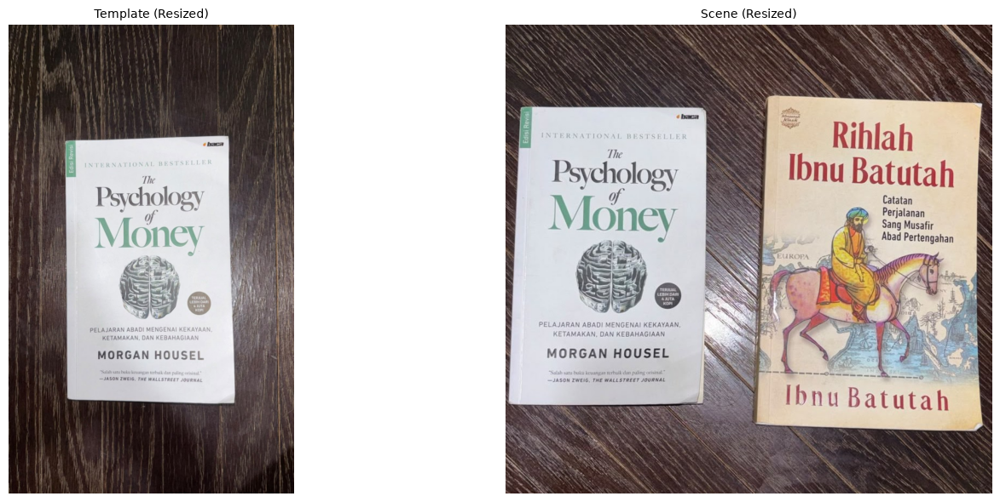

In [27]:
# Tahap 1: Load & Resize
template_img = load_image(demo_template_path, max_side=1000)
scene_img = load_image(demo_scene_path, max_side=1000)

print(f"Ukuran template setelah resize: {template_img.shape}")
print(f"Ukuran scene setelah resize   : {scene_img.shape}")

show_images([template_img, scene_img], 
            ['Template (Resized)', 'Scene (Resized)'],
            cols=2, figsize=(16, 6))

### Tahap 2: Konversi ke Grayscale (Prak 3)

Deteksi fitur (ORB/SIFT) bekerja pada citra grayscale karena mendeteksi gradien intensitas.

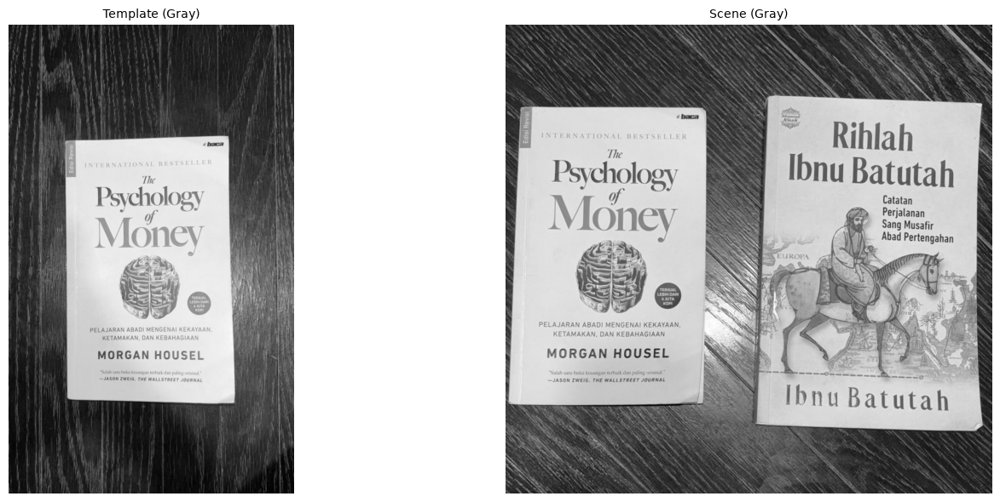

In [20]:
# Tahap 2: Grayscale
gray_template = to_grayscale(template_img)
gray_scene = to_grayscale(scene_img)

show_images([gray_template, gray_scene], 
            ['Template (Gray)', 'Scene (Gray)'],
            cols=2, figsize=(16, 6))

### Tahap 3: Deteksi Keypoint & Deskriptor (Prak 5: ORB)

ORB mendeteksi sudut-sudut (corners) yang menonjol sebagai keypoint, lalu menghitung deskriptor biner di sekitar setiap keypoint.  
Parameter `nfeatures=5000` digunakan agar keypoint cukup banyak (default ORB hanya 500).

Keypoints template: 4801
Keypoints scene   : 5000


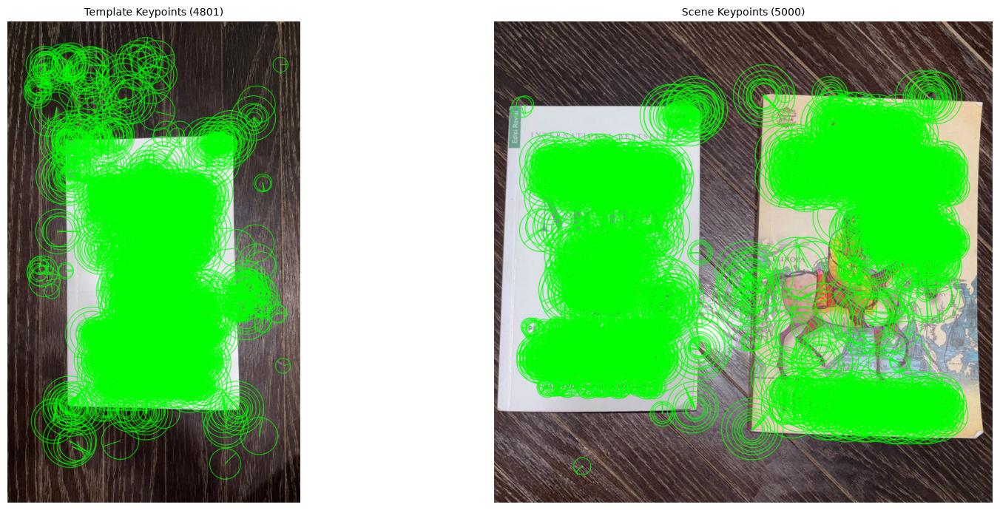

In [21]:
# Tahap 3: Deteksi Fitur dengan ORB
kp_t, desc_t = detect_features(gray_template, method='ORB', nfeatures=5000)
kp_s, desc_s = detect_features(gray_scene, method='ORB', nfeatures=5000)

print(f"Keypoints template: {len(kp_t)}")
print(f"Keypoints scene   : {len(kp_s)}")

# Visualisasi keypoints
kp_img_t = cv2.drawKeypoints(template_img, kp_t, None, 
                              color=(0, 255, 0), 
                              flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
kp_img_s = cv2.drawKeypoints(scene_img, kp_s, None, 
                              color=(0, 255, 0), 
                              flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

show_images([kp_img_t, kp_img_s], 
            [f'Template Keypoints ({len(kp_t)})', f'Scene Keypoints ({len(kp_s)})'],
            cols=2, figsize=(18, 7))

### Tahap 4: Feature Matching — BFMatcher + Lowe's Ratio Test (Prak 5)

- BFMatcher mencocokkan setiap deskriptor template dengan semua deskriptor scene.
- `knnMatch(k=2)` mengembalikan 2 kandidat terdekat.
- **Ratio test**: match diterima jika `distance_terbaik < 0.75 × distance_kedua`.  
  Ini menyaring match yang ambigu (dua kandidat jaraknya hampir sama → kemungkinan salah).

Good matches: 873


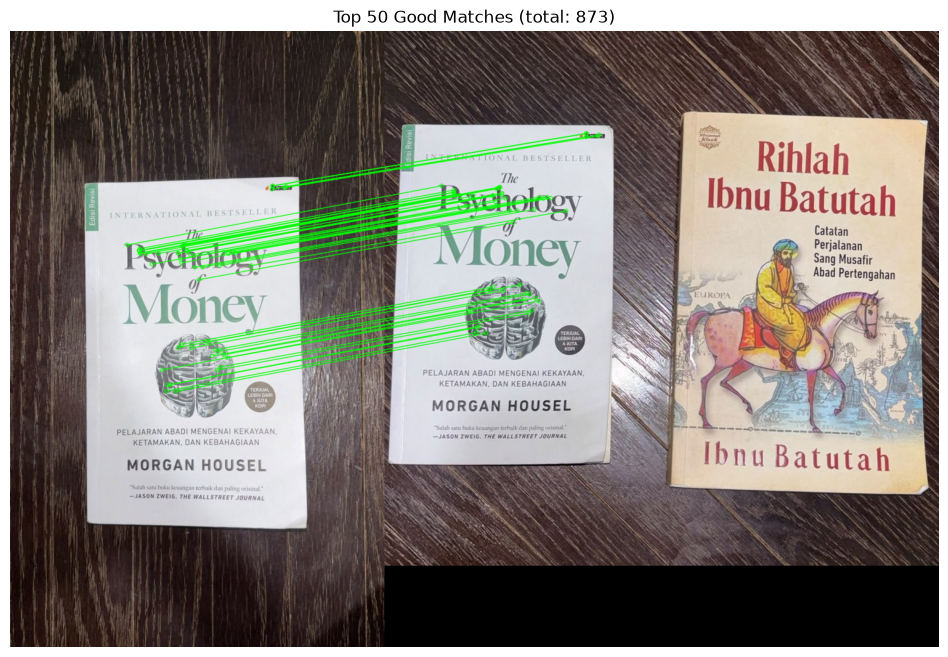

In [22]:
# Tahap 4: Matching
good_matches = match_features(desc_t, desc_s, method='ORB', ratio=0.75)

print(f"Good matches: {len(good_matches)}")

# Visualisasi top 50 matches
good_sorted = sorted(good_matches, key=lambda x: x.distance)
match_vis = cv2.drawMatches(
    template_img, kp_t,
    scene_img, kp_s,
    good_sorted[:50], None,
    matchColor=(0, 255, 0),
    singlePointColor=(255, 0, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

show_single(match_vis, f'Top 50 Good Matches (total: {len(good_matches)})', 
            figsize=(18, 8))

### Tahap 5: Homography + perspectiveTransform (Prak 5)

- `findHomography(RANSAC)` menghitung matriks transformasi 3×3 dari titik-titik template ke scene.
- RANSAC secara iteratif mencari subset match yang konsisten, menyingkirkan outlier.
- `perspectiveTransform` mentransformasikan 4 sudut template ke koordinat di scene.
- Validasi: area poligon harus masuk akal dan poligon harus convex.

In [23]:
# Tahap 5: Homography
found, corners, mask = find_book_in_scene(
    kp_t, kp_s, good_matches, gray_template.shape, min_match_count=10
)

if found:
    inlier_count = int(mask.sum())
    print(f"Buku DITEMUKAN!")
    print(f"Inlier: {inlier_count}/{len(good_matches)} "
          f"({inlier_count/len(good_matches)*100:.1f}%)")
    print(f"Sudut buku di scene:")
    for i, pt in enumerate(corners.reshape(-1, 2)):
        print(f"  Sudut {i+1}: ({pt[0]:.0f}, {pt[1]:.0f})")
else:
    print("Buku TIDAK DITEMUKAN")
    print(f"Good matches hanya: {len(good_matches)}")

Buku DITEMUKAN!
Inlier: 792/873 (90.7%)
Sudut buku di scene:
  Sudut 1: (-95, -112)
  Sudut 2: (515, -62)
  Sudut 3: (483, 896)
  Sudut 4: (-137, 916)


### Tahap 6: Visualisasi Hasil Akhir (Prak 4)

Gambar poligon 4 sisi di lokasi buku yang ditemukan, atau tampilkan pesan "Tidak Ditemukan".

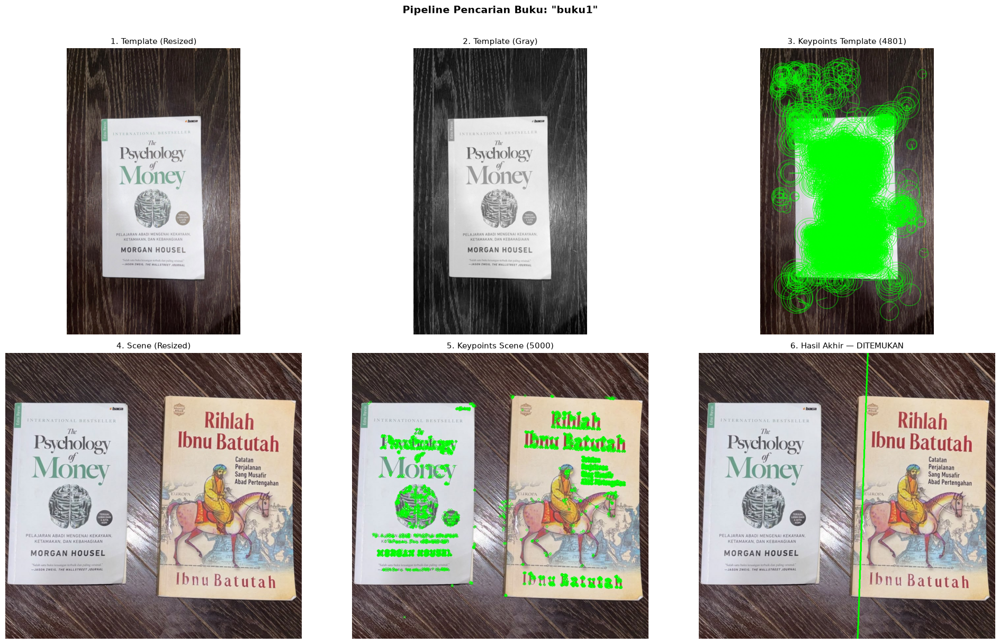

Hasil disimpan: output\demo_pipeline_buku1.jpg


In [28]:
# Tahap 6: Hasil Akhir
result = draw_result(scene_img, demo_template_name, found, corners, len(good_matches))

# Tampilkan pipeline lengkap: Asli → Gray → Keypoints → Matching → Hasil
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# Baris 1: Template
axes[0, 0].imshow(cv2.cvtColor(template_img, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title('1. Template (Resized)', fontsize=11)

axes[0, 1].imshow(gray_template, cmap='gray')
axes[0, 1].set_title('2. Template (Gray)', fontsize=11)

axes[0, 2].imshow(cv2.cvtColor(kp_img_t, cv2.COLOR_BGR2RGB))
axes[0, 2].set_title(f'3. Keypoints Template ({len(kp_t)})', fontsize=11)

# Baris 2: Scene
axes[1, 0].imshow(cv2.cvtColor(scene_img, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title('4. Scene (Resized)', fontsize=11)

kp_img_s_small = cv2.drawKeypoints(scene_img, kp_s, None, color=(0, 255, 0),
                                    flags=cv2.DRAW_MATCHES_FLAGS_DEFAULT)
axes[1, 1].imshow(cv2.cvtColor(kp_img_s_small, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title(f'5. Keypoints Scene ({len(kp_s)})', fontsize=11)

axes[1, 2].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
status = 'DITEMUKAN' if found else 'TIDAK DITEMUKAN'
axes[1, 2].set_title(f'6. Hasil Akhir — {status}', fontsize=11)

for ax in axes.flatten():
    ax.axis('off')

plt.suptitle(f'Pipeline Pencarian Buku: "{demo_template_name}"', 
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Simpan hasil
output_path = os.path.join(OUTPUT_DIR, f'demo_pipeline_{demo_template_name}.jpg')
cv2.imwrite(output_path, result)
print(f"Hasil disimpan: {output_path}")

Visualisasi Garis Matching (Template ↔ Scene):


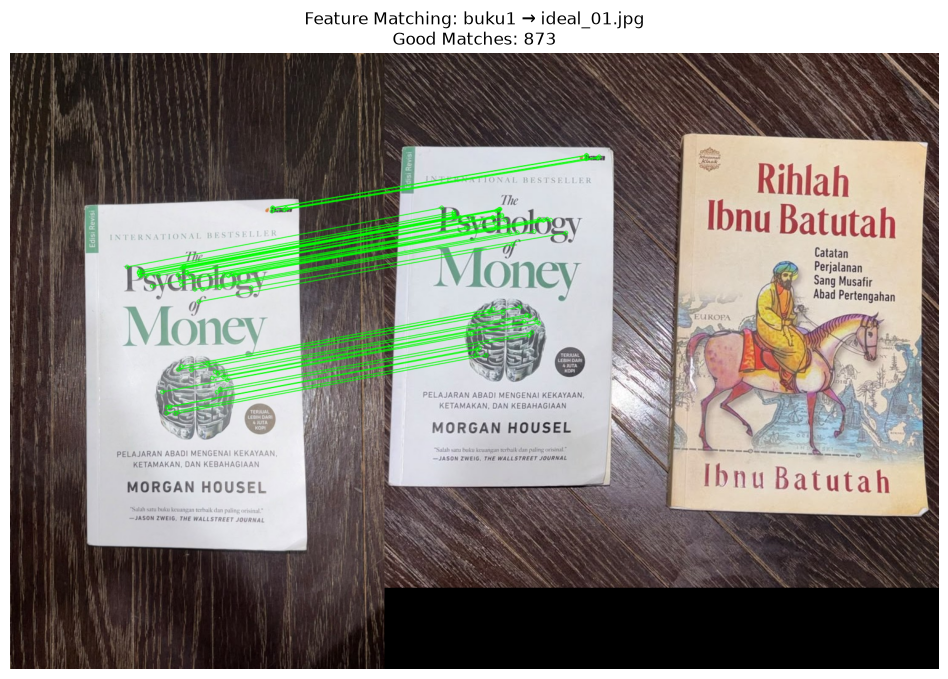

In [29]:
# Tampilkan visualisasi matching lines
print("Visualisasi Garis Matching (Template ↔ Scene):")
show_single(match_vis, 
            f'Feature Matching: {demo_template_name} → {os.path.basename(demo_scene_path)}\n'
            f'Good Matches: {len(good_matches)}',
            figsize=(20, 8))

---
## 4. Evaluasi: Jalankan Pipeline ke Seluruh Dataset

Pipeline dijalankan untuk **setiap kombinasi template × scene**, lalu dibandingkan dengan ground truth.  
Metrik evaluasi:
- **True Positive (TP)**: Buku ada dan terdeteksi
- **False Positive (FP)**: Buku tidak ada tapi terdeteksi (salah deteksi)
- **True Negative (TN)**: Buku tidak ada dan tidak terdeteksi
- **False Negative (FN)**: Buku ada tapi tidak terdeteksi
- **Akurasi** = (TP + TN) / total

In [31]:
def get_ground_truth_for_file(filename, ground_truth_list):
    """
    Mencari ground truth untuk file tertentu.
    Returns: dict atau None
    """
    for gt in ground_truth_list:
        if gt['file'] == filename:
            return gt
    return None


def evaluate_pipeline(template_paths, scene_files, ground_truth, 
                      method='ORB', ratio=0.75, min_match_count=10,
                      nfeatures=5000):
    """
    Jalankan pipeline ke seluruh dataset dan evaluasi.
    
    Returns:
    --------
    results : list of dict
        Hasil per citra per template
    summary : dict
        Rangkuman akurasi per kondisi
    """
    results = []
    
    for kondisi, paths in scene_files.items():
        for scene_path in paths:
            scene_filename = os.path.basename(scene_path)
            gt = get_ground_truth_for_file(scene_filename, ground_truth)
            
            for tpl_name, tpl_path in template_paths.items():
                # Jalankan pipeline
                res = search_book(
                    tpl_path, scene_path, 
                    method=method, ratio=ratio,
                    min_match_count=min_match_count,
                    nfeatures=nfeatures
                )
                
                # Tentukan ground truth untuk template ini
                gt_present = False
                if gt and tpl_name in gt.get('buku_target', []):
                    gt_present = True
                
                # Hitung TP/FP/TN/FN
                detected = res['found']
                if gt_present and detected:
                    category = 'TP'
                elif gt_present and not detected:
                    category = 'FN'
                elif not gt_present and detected:
                    category = 'FP'
                else:
                    category = 'TN'
                
                results.append({
                    'scene_file': scene_filename,
                    'kondisi': kondisi,
                    'template': tpl_name,
                    'gt_present': gt_present,
                    'detected': detected,
                    'category': category,
                    'good_matches': res['num_good_matches'],
                    'kp_template': res['num_keypoints_template'],
                    'kp_scene': res['num_keypoints_scene'],
                    'time': res['time_seconds'],
                    'method': method,
                    'ratio': ratio
                })
    
    # Hitung summary per kondisi
    summary = {}
    for kondisi in KONDISI_LIST:
        kondisi_results = [r for r in results if r['kondisi'] == kondisi]
        if not kondisi_results:
            continue
        
        tp = sum(1 for r in kondisi_results if r['category'] == 'TP')
        fp = sum(1 for r in kondisi_results if r['category'] == 'FP')
        tn = sum(1 for r in kondisi_results if r['category'] == 'TN')
        fn = sum(1 for r in kondisi_results if r['category'] == 'FN')
        total = len(kondisi_results)
        accuracy = (tp + tn) / total * 100 if total > 0 else 0
        
        summary[kondisi] = {
            'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
            'total': total, 'accuracy': accuracy
        }
    
    # Akurasi keseluruhan
    tp_all = sum(1 for r in results if r['category'] == 'TP')
    fp_all = sum(1 for r in results if r['category'] == 'FP')
    tn_all = sum(1 for r in results if r['category'] == 'TN')
    fn_all = sum(1 for r in results if r['category'] == 'FN')
    total_all = len(results)
    accuracy_all = (tp_all + tn_all) / total_all * 100 if total_all > 0 else 0
    
    summary['overall'] = {
        'TP': tp_all, 'FP': fp_all, 'TN': tn_all, 'FN': fn_all,
        'total': total_all, 'accuracy': accuracy_all
    }
    
    return results, summary

In [32]:
# ============================================================
# Jalankan evaluasi dengan ORB (metode utama)
# ============================================================
print("Menjalankan evaluasi pipeline (ORB, ratio=0.75)...")
print("Ini mungkin memakan waktu beberapa menit.\n")

results_orb, summary_orb = evaluate_pipeline(
    template_paths, scene_files, ground_truth,
    method='ORB', ratio=0.75, min_match_count=10, nfeatures=5000
)

print("Evaluasi selesai!")
print(f"Total evaluasi: {len(results_orb)} (= {len(template_paths)} template × {total_scenes} scene)")

Menjalankan evaluasi pipeline (ORB, ratio=0.75)...
Ini mungkin memakan waktu beberapa menit.

Evaluasi selesai!
Total evaluasi: 100 (= 5 template × 20 scene)


In [33]:
# ============================================================
# Tabel Hasil per Citra
# ============================================================
print("=" * 95)
print(f"{'Scene':<20} {'Kondisi':<15} {'Template':<12} {'GT':<6} {'Det':<6} {'Cat':<5} {'Matches':<8} {'Time(s)'}")
print("=" * 95)

for r in results_orb:
    gt_str = 'Ada' if r['gt_present'] else '-'
    det_str = 'Ya' if r['detected'] else 'Tidak'
    print(f"{r['scene_file']:<20} {r['kondisi']:<15} {r['template']:<12} "
          f"{gt_str:<6} {det_str:<6} {r['category']:<5} {r['good_matches']:<8} {r['time']:.3f}")

Scene                Kondisi         Template     GT     Det    Cat   Matches  Time(s)
ideal_01.jpg         ideal           buku1        Ada    Ya     TP    873      0.099
ideal_01.jpg         ideal           buku2        -      Tidak  TN    55       0.132
ideal_01.jpg         ideal           buku3        Ada    Ya     TP    924      0.106
ideal_01.jpg         ideal           buku4        -      Tidak  TN    33       0.124
ideal_01.jpg         ideal           buku5        -      Tidak  TN    39       0.135
ideal_02.jpg         ideal           buku1        -      Tidak  TN    39       0.141
ideal_02.jpg         ideal           buku2        Ada    Ya     TP    515      0.085
ideal_02.jpg         ideal           buku3        -      Tidak  TN    49       0.126
ideal_02.jpg         ideal           buku4        Ada    Ya     TP    240      0.089
ideal_02.jpg         ideal           buku5        -      Tidak  TN    33       0.128
ideal_03.jpg         ideal           buku1        Ada    Ya    

In [34]:
# ============================================================
# Tabel Akurasi per Kondisi
# ============================================================
print("\n" + "=" * 70)
print("AKURASI PER KONDISI (ORB, ratio=0.75)")
print("=" * 70)
print(f"{'Kondisi':<18} {'TP':<6} {'FP':<6} {'TN':<6} {'FN':<6} {'Total':<8} {'Akurasi'}")
print("-" * 70)

for kondisi in KONDISI_LIST + ['overall']:
    if kondisi in summary_orb:
        s = summary_orb[kondisi]
        label = kondisi.upper() if kondisi == 'overall' else kondisi
        print(f"{label:<18} {s['TP']:<6} {s['FP']:<6} {s['TN']:<6} {s['FN']:<6} "
              f"{s['total']:<8} {s['accuracy']:.1f}%")

print("=" * 70)


AKURASI PER KONDISI (ORB, ratio=0.75)
Kondisi            TP     FP     TN     FN     Total    Akurasi
----------------------------------------------------------------------
ideal              19     0      20     1      40       97.5%
sudut              7      0      21     2      30       93.3%
tertutup           5      1      9      0      15       93.3%
tanpa_target       0      0      15     0      15       100.0%
OVERALL            31     1      65     3      100      96.0%


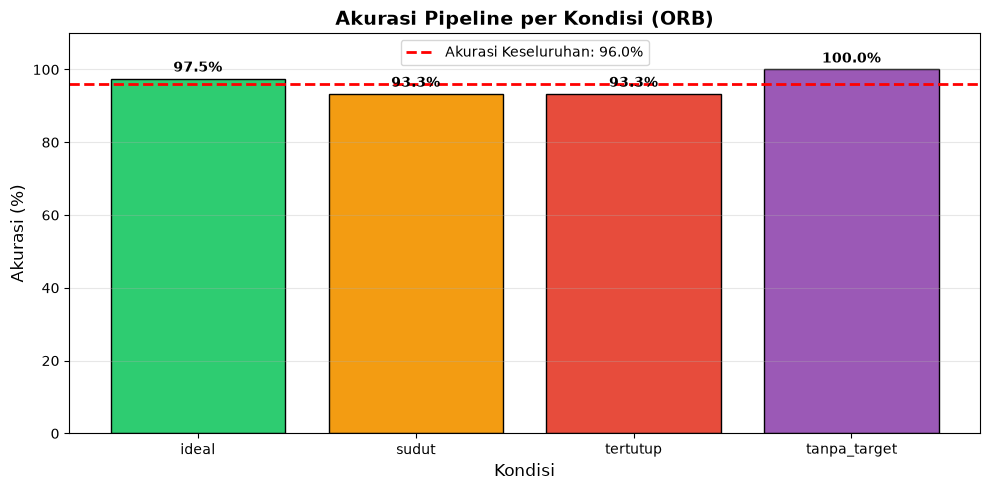

In [35]:
# ============================================================
# Visualisasi Akurasi per Kondisi (Bar Chart)
# ============================================================
kondisi_labels = [k for k in KONDISI_LIST if k in summary_orb]
akurasi_values = [summary_orb[k]['accuracy'] for k in kondisi_labels]

if kondisi_labels:
    colors = ['#2ecc71', '#f39c12', '#e74c3c', '#9b59b6']
    
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(kondisi_labels, akurasi_values, 
                  color=colors[:len(kondisi_labels)], edgecolor='black')
    
    # Tambah label di atas bar
    for bar, val in zip(bars, akurasi_values):
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
                f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
    
    # Garis akurasi keseluruhan
    if 'overall' in summary_orb:
        ax.axhline(y=summary_orb['overall']['accuracy'], 
                   color='red', linestyle='--', linewidth=2,
                   label=f"Akurasi Keseluruhan: {summary_orb['overall']['accuracy']:.1f}%")
    
    ax.set_xlabel('Kondisi', fontsize=12)
    ax.set_ylabel('Akurasi (%)', fontsize=12)
    ax.set_title('Akurasi Pipeline per Kondisi (ORB)', fontsize=14, fontweight='bold')
    ax.set_ylim(0, 110)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

### 4.1 Contoh Hasil Deteksi per Kondisi

Tampilkan hasil visual pipeline pada 1 contoh per kondisi.


--- Kondisi: ideal | Scene: ideal_01.jpg ---
    Matches: 873, Ditemukan: True


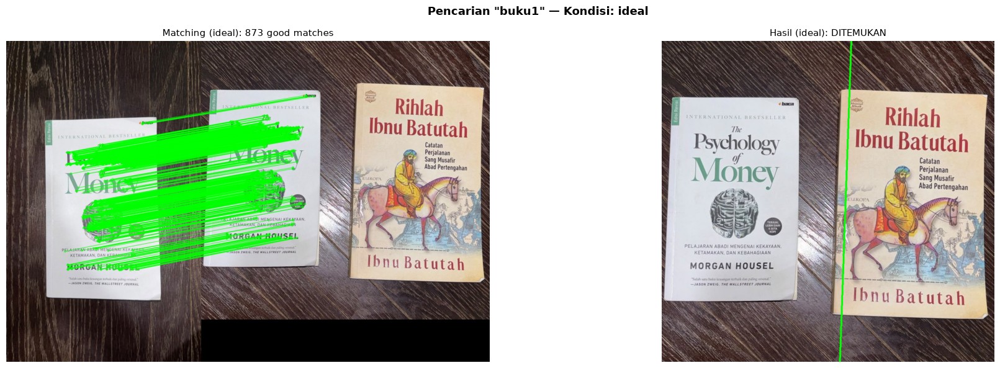


--- Kondisi: sudut | Scene: sudut_01.jpg ---
    Matches: 135, Ditemukan: True


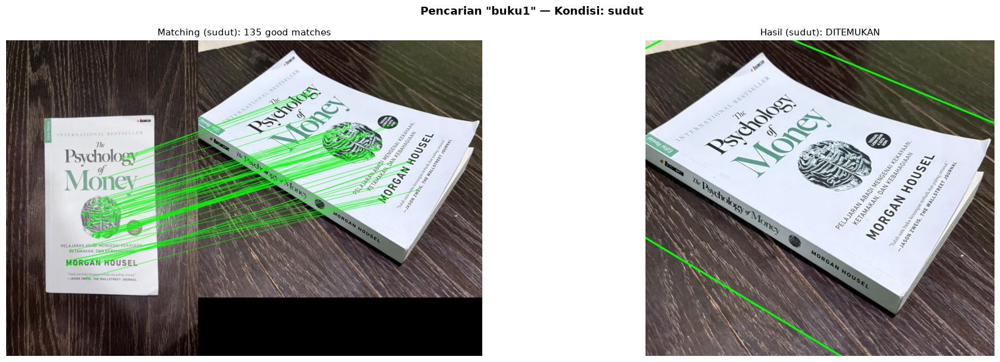


--- Kondisi: tertutup | Scene: tertutup_01.jpg ---
    Matches: 309, Ditemukan: True


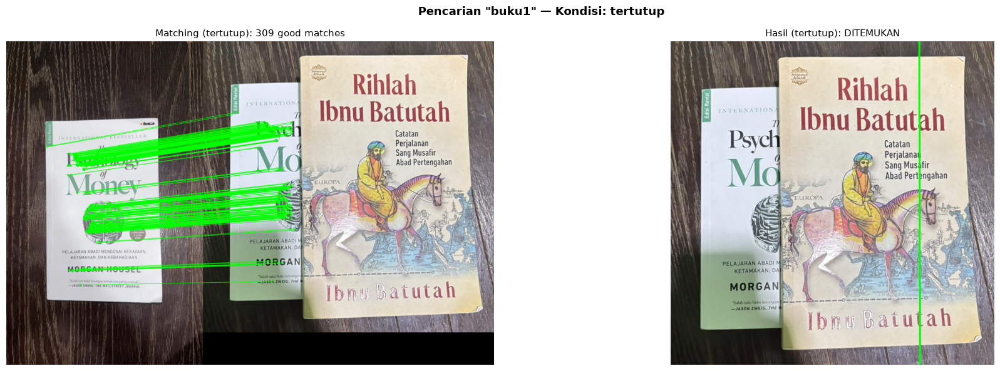


--- Kondisi: tanpa_target | Scene: tanpa_01.jpg ---
    Matches: 35, Ditemukan: False


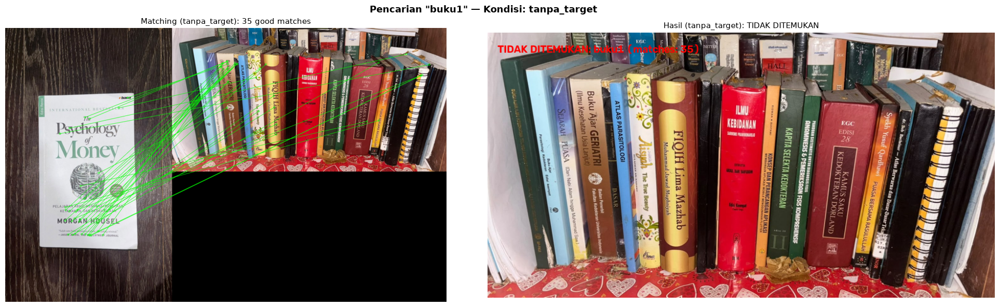

In [36]:
# Tampilkan contoh hasil per kondisi
demo_template_name = list(template_paths.keys())[0]
demo_template_path = template_paths[demo_template_name]

for kondisi in KONDISI_LIST:
    if not scene_files.get(kondisi):
        continue
    
    scene_path = scene_files[kondisi][0]
    res = search_book(demo_template_path, scene_path, method='ORB', ratio=0.75)
    
    print(f"\n--- Kondisi: {kondisi} | Scene: {os.path.basename(scene_path)} ---")
    print(f"    Matches: {res['num_good_matches']}, Ditemukan: {res['found']}")
    
    # Tampilkan matching dan hasil
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))
    
    axes[0].imshow(cv2.cvtColor(res['match_img'], cv2.COLOR_BGR2RGB))
    axes[0].set_title(f'Matching ({kondisi}): {res["num_good_matches"]} good matches', fontsize=11)
    axes[0].axis('off')
    
    axes[1].imshow(cv2.cvtColor(res['result_img'], cv2.COLOR_BGR2RGB))
    status = 'DITEMUKAN' if res['found'] else 'TIDAK DITEMUKAN'
    axes[1].set_title(f'Hasil ({kondisi}): {status}', fontsize=11)
    axes[1].axis('off')
    
    plt.suptitle(f'Pencarian "{demo_template_name}" — Kondisi: {kondisi}', 
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Simpan hasil
    out_name = f'hasil_{kondisi}_{os.path.basename(scene_path)}'
    cv2.imwrite(os.path.join(OUTPUT_DIR, out_name), res['result_img'])

---
## 5. Eksperimen Pembanding

### Eksperimen 1: ORB vs SIFT

Membandingkan performa dua metode deteksi fitur:

| Aspek | ORB | SIFT |
|---|---|---|
| Deskriptor | Biner (256 bit) | Float (128 dimensi) |
| Norm | Hamming | L2 |
| Kecepatan | Lebih cepat | Lebih lambat |
| Invarian Skala | Terbatas | Bagus |
| Lisensi | Gratis | Gratis (sejak OpenCV 4.4) |

In [37]:
# ============================================================
# Eksperimen 1: ORB vs SIFT
# ============================================================
print("Menjalankan evaluasi SIFT (ratio=0.75)...\n")

results_sift, summary_sift = evaluate_pipeline(
    template_paths, scene_files, ground_truth,
    method='SIFT', ratio=0.75, min_match_count=10, nfeatures=5000
)

print("Evaluasi SIFT selesai!")

Menjalankan evaluasi SIFT (ratio=0.75)...

Evaluasi SIFT selesai!


In [38]:
# ============================================================
# Tabel Perbandingan ORB vs SIFT
# ============================================================
print("\n" + "=" * 85)
print("PERBANDINGAN ORB vs SIFT")
print("=" * 85)
print(f"{'Kondisi':<18} {'ORB Akurasi':<15} {'SIFT Akurasi':<15} {'ORB Avg Match':<15} {'SIFT Avg Match'}")
print("-" * 85)

for kondisi in KONDISI_LIST + ['overall']:
    label = kondisi.upper() if kondisi == 'overall' else kondisi
    
    orb_acc = summary_orb.get(kondisi, {}).get('accuracy', 0)
    sift_acc = summary_sift.get(kondisi, {}).get('accuracy', 0)
    
    # Rata-rata good matches
    orb_matches = [r['good_matches'] for r in results_orb if r['kondisi'] == kondisi]
    sift_matches = [r['good_matches'] for r in results_sift if r['kondisi'] == kondisi]
    
    orb_avg = np.mean(orb_matches) if orb_matches else 0
    sift_avg = np.mean(sift_matches) if sift_matches else 0
    
    if kondisi == 'overall':
        orb_avg = np.mean([r['good_matches'] for r in results_orb])
        sift_avg = np.mean([r['good_matches'] for r in results_sift])
    
    print(f"{label:<18} {orb_acc:<15.1f} {sift_acc:<15.1f} {orb_avg:<15.1f} {sift_avg:.1f}")

print("=" * 85)

# Rata-rata waktu
orb_time = np.mean([r['time'] for r in results_orb])
sift_time = np.mean([r['time'] for r in results_sift])
print(f"\nRata-rata waktu per deteksi: ORB = {orb_time:.3f}s, SIFT = {sift_time:.3f}s")
print(f"SIFT {sift_time/orb_time:.1f}× lebih lambat dari ORB")


PERBANDINGAN ORB vs SIFT
Kondisi            ORB Akurasi     SIFT Akurasi    ORB Avg Match   SIFT Avg Match
-------------------------------------------------------------------------------------
ideal              97.5            92.5            330.2           319.4
sudut              93.3            86.7            54.5            87.8
tertutup           93.3            80.0            212.6           260.5
tanpa_target       100.0           100.0           36.4            66.1
OVERALL            96.0            90.0            185.8           203.1

Rata-rata waktu per deteksi: ORB = 0.119s, SIFT = 0.305s
SIFT 2.6× lebih lambat dari ORB


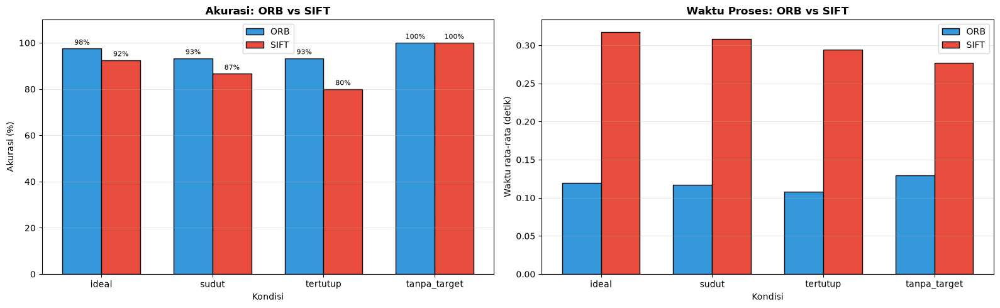

In [39]:
# ============================================================
# Visualisasi Perbandingan ORB vs SIFT
# ============================================================
kondisi_labels = [k for k in KONDISI_LIST if k in summary_orb and k in summary_sift]

if kondisi_labels:
    orb_accs = [summary_orb[k]['accuracy'] for k in kondisi_labels]
    sift_accs = [summary_sift[k]['accuracy'] for k in kondisi_labels]
    
    x = np.arange(len(kondisi_labels))
    width = 0.35
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    # Subplot 1: Akurasi
    bars1 = axes[0].bar(x - width/2, orb_accs, width, label='ORB', color='#3498db', edgecolor='black')
    bars2 = axes[0].bar(x + width/2, sift_accs, width, label='SIFT', color='#e74c3c', edgecolor='black')
    
    axes[0].set_xlabel('Kondisi')
    axes[0].set_ylabel('Akurasi (%)')
    axes[0].set_title('Akurasi: ORB vs SIFT', fontweight='bold')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(kondisi_labels)
    axes[0].set_ylim(0, 110)
    axes[0].legend()
    axes[0].grid(axis='y', alpha=0.3)
    
    # Label di atas bar
    for bar, val in zip(bars1, orb_accs):
        axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
                     f'{val:.0f}%', ha='center', va='bottom', fontsize=8)
    for bar, val in zip(bars2, sift_accs):
        axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
                     f'{val:.0f}%', ha='center', va='bottom', fontsize=8)
    
    # Subplot 2: Waktu
    orb_times = [np.mean([r['time'] for r in results_orb if r['kondisi'] == k]) for k in kondisi_labels]
    sift_times = [np.mean([r['time'] for r in results_sift if r['kondisi'] == k]) for k in kondisi_labels]
    
    bars3 = axes[1].bar(x - width/2, orb_times, width, label='ORB', color='#3498db', edgecolor='black')
    bars4 = axes[1].bar(x + width/2, sift_times, width, label='SIFT', color='#e74c3c', edgecolor='black')
    
    axes[1].set_xlabel('Kondisi')
    axes[1].set_ylabel('Waktu rata-rata (detik)')
    axes[1].set_title('Waktu Proses: ORB vs SIFT', fontweight='bold')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(kondisi_labels)
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

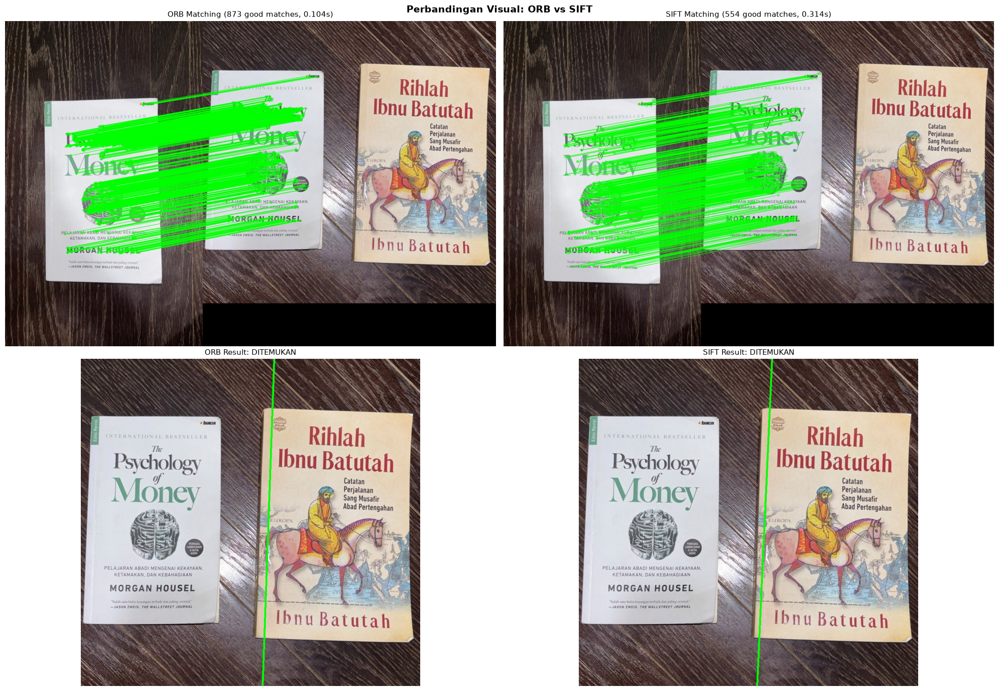

In [40]:
# ============================================================
# Visualisasi ORB vs SIFT pada satu contoh
# ============================================================
demo_template_path_exp = template_paths[list(template_paths.keys())[0]]
demo_scene_path_exp = scene_files['ideal'][0] if scene_files.get('ideal') else None

if demo_scene_path_exp:
    res_orb = search_book(demo_template_path_exp, demo_scene_path_exp, method='ORB', ratio=0.75)
    res_sift = search_book(demo_template_path_exp, demo_scene_path_exp, method='SIFT', ratio=0.75)
    
    fig, axes = plt.subplots(2, 2, figsize=(20, 14))
    
    axes[0, 0].imshow(cv2.cvtColor(res_orb['match_img'], cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title(f'ORB Matching ({res_orb["num_good_matches"]} good matches, '
                          f'{res_orb["time_seconds"]:.3f}s)', fontsize=11)
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(cv2.cvtColor(res_sift['match_img'], cv2.COLOR_BGR2RGB))
    axes[0, 1].set_title(f'SIFT Matching ({res_sift["num_good_matches"]} good matches, '
                          f'{res_sift["time_seconds"]:.3f}s)', fontsize=11)
    axes[0, 1].axis('off')
    
    axes[1, 0].imshow(cv2.cvtColor(res_orb['result_img'], cv2.COLOR_BGR2RGB))
    status_orb = 'DITEMUKAN' if res_orb['found'] else 'TIDAK DITEMUKAN'
    axes[1, 0].set_title(f'ORB Result: {status_orb}', fontsize=11)
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(cv2.cvtColor(res_sift['result_img'], cv2.COLOR_BGR2RGB))
    status_sift = 'DITEMUKAN' if res_sift['found'] else 'TIDAK DITEMUKAN'
    axes[1, 1].set_title(f'SIFT Result: {status_sift}', fontsize=11)
    axes[1, 1].axis('off')
    
    plt.suptitle('Perbandingan Visual: ORB vs SIFT', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

### Eksperimen 2: Pengaruh Nilai Ratio Test (0.6 / 0.7 / 0.8)

Ratio test menentukan seberapa ketat penyaringan match:
- **Ratio kecil (0.6)**: Sangat ketat, sedikit match tapi akurat.
- **Ratio besar (0.8)**: Longgar, banyak match tapi mungkin ada yang salah.
- **Optimal**: Keseimbangan antara jumlah match dan akurasi.

In [41]:
# ============================================================
# Eksperimen 2: Pengaruh Ratio Test
# ============================================================
ratio_values = [0.6, 0.7, 0.8]
ratio_results = {}
ratio_summaries = {}

for ratio_val in ratio_values:
    print(f"Menjalankan evaluasi ORB dengan ratio={ratio_val}...")
    res, summ = evaluate_pipeline(
        template_paths, scene_files, ground_truth,
        method='ORB', ratio=ratio_val, min_match_count=10, nfeatures=5000
    )
    ratio_results[ratio_val] = res
    ratio_summaries[ratio_val] = summ

print("\nSelesai!")

Menjalankan evaluasi ORB dengan ratio=0.6...
Menjalankan evaluasi ORB dengan ratio=0.7...
Menjalankan evaluasi ORB dengan ratio=0.8...

Selesai!


In [42]:
# ============================================================
# Tabel Perbandingan Ratio Test
# ============================================================
print("\n" + "=" * 75)
print("PENGARUH RATIO TEST TERHADAP AKURASI (ORB)")
print("=" * 75)
print(f"{'Kondisi':<18}", end='')
for r in ratio_values:
    print(f"{'Ratio='+str(r):<18}", end='')
print()
print("-" * 75)

for kondisi in KONDISI_LIST + ['overall']:
    label = kondisi.upper() if kondisi == 'overall' else kondisi
    print(f"{label:<18}", end='')
    for r in ratio_values:
        acc = ratio_summaries[r].get(kondisi, {}).get('accuracy', 0)
        print(f"{acc:<18.1f}", end='')
    print()

print("=" * 75)

# Rata-rata good matches per ratio
print("\nRata-rata Good Matches per ratio:")
for r in ratio_values:
    avg_m = np.mean([res['good_matches'] for res in ratio_results[r]])
    print(f"  Ratio {r}: {avg_m:.1f} matches")


PENGARUH RATIO TEST TERHADAP AKURASI (ORB)
Kondisi           Ratio=0.6         Ratio=0.7         Ratio=0.8         
---------------------------------------------------------------------------
ideal             97.5              97.5              95.0              
sudut             83.3              93.3              90.0              
tertutup          93.3              93.3              93.3              
tanpa_target      100.0             100.0             100.0             
OVERALL           93.0              96.0              94.0              

Rata-rata Good Matches per ratio:
  Ratio 0.6: 94.4 matches
  Ratio 0.7: 140.4 matches
  Ratio 0.8: 282.8 matches


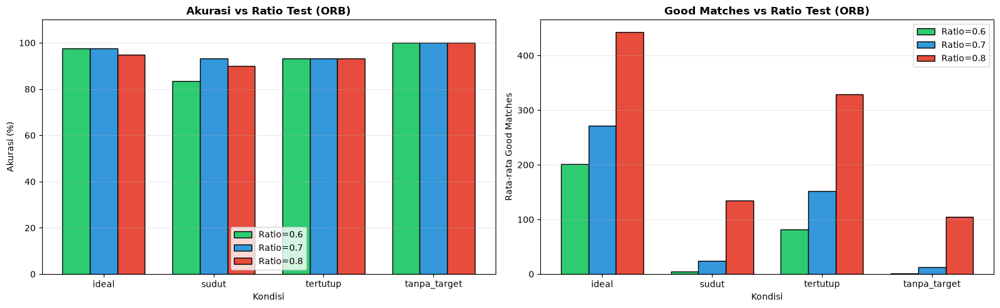

In [43]:
# ============================================================
# Visualisasi Pengaruh Ratio Test
# ============================================================
kondisi_labels = [k for k in KONDISI_LIST if k in ratio_summaries[ratio_values[0]]]

if kondisi_labels:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    x = np.arange(len(kondisi_labels))
    width = 0.25
    colors_ratio = ['#2ecc71', '#3498db', '#e74c3c']
    
    # Subplot 1: Akurasi per ratio
    for i, r in enumerate(ratio_values):
        accs = [ratio_summaries[r][k]['accuracy'] for k in kondisi_labels]
        axes[0].bar(x + (i - 1) * width, accs, width, 
                    label=f'Ratio={r}', color=colors_ratio[i], edgecolor='black')
    
    axes[0].set_xlabel('Kondisi')
    axes[0].set_ylabel('Akurasi (%)')
    axes[0].set_title('Akurasi vs Ratio Test (ORB)', fontweight='bold')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(kondisi_labels)
    axes[0].set_ylim(0, 110)
    axes[0].legend()
    axes[0].grid(axis='y', alpha=0.3)
    
    # Subplot 2: Rata-rata good matches per ratio
    for i, r in enumerate(ratio_values):
        avg_matches = [np.mean([res['good_matches'] for res in ratio_results[r] 
                               if res['kondisi'] == k]) for k in kondisi_labels]
        axes[1].bar(x + (i - 1) * width, avg_matches, width,
                    label=f'Ratio={r}', color=colors_ratio[i], edgecolor='black')
    
    axes[1].set_xlabel('Kondisi')
    axes[1].set_ylabel('Rata-rata Good Matches')
    axes[1].set_title('Good Matches vs Ratio Test (ORB)', fontweight='bold')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(kondisi_labels)
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

---
## 6. Analisis Kegagalan

Tampilkan  hasil yang gagal (False Positive atau False Negative) dan analisis penyebabnya.

In [44]:
# ============================================================
# Kumpulkan kasus gagal
# ============================================================
failures = [r for r in results_orb if r['category'] in ('FP', 'FN')]

print(f"Total kasus gagal: {len(failures)}")
print(f"  - False Positive (salah deteksi): {sum(1 for r in failures if r['category'] == 'FP')}")
print(f"  - False Negative (gagal deteksi): {sum(1 for r in failures if r['category'] == 'FN')}")

Total kasus gagal: 4
  - False Positive (salah deteksi): 1
  - False Negative (gagal deteksi): 3



KASUS GAGAL #1: FN
  Scene    : ideal_08.jpg (kondisi: ideal)
  Template : buku5
  GT Ada?  : Ya
  Terdeteksi? : Tidak
  Good Matches: 41
  Analisis: Buku ada di foto tapi tidak terdeteksi.
    Kemungkinan penyebab:
    - Pencahayaan atau skala berbeda signifikan


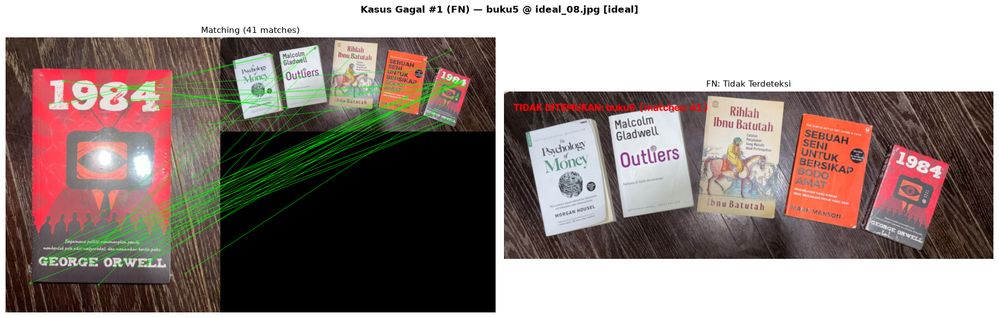


KASUS GAGAL #2: FN
  Scene    : sudut_02.jpg (kondisi: sudut)
  Template : buku3
  GT Ada?  : Ya
  Terdeteksi? : Tidak
  Good Matches: 63
  Analisis: Buku ada di foto tapi tidak terdeteksi.
    Kemungkinan penyebab:
    - Buku difoto dari sudut miring → perubahan perspektif terlalu besar
    - Keypoint tidak cukup cocok karena distorsi


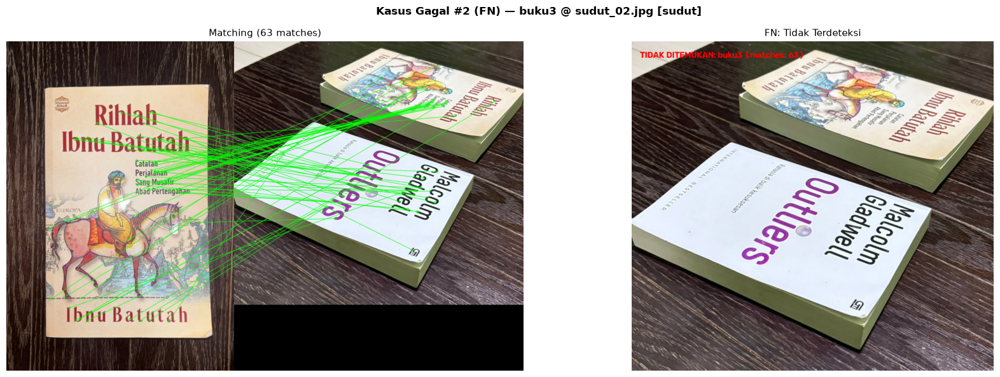


KASUS GAGAL #3: FN
  Scene    : sudut_06.jpg (kondisi: sudut)
  Template : buku5
  GT Ada?  : Ya
  Terdeteksi? : Tidak
  Good Matches: 49
  Analisis: Buku ada di foto tapi tidak terdeteksi.
    Kemungkinan penyebab:
    - Buku difoto dari sudut miring → perubahan perspektif terlalu besar
    - Keypoint tidak cukup cocok karena distorsi


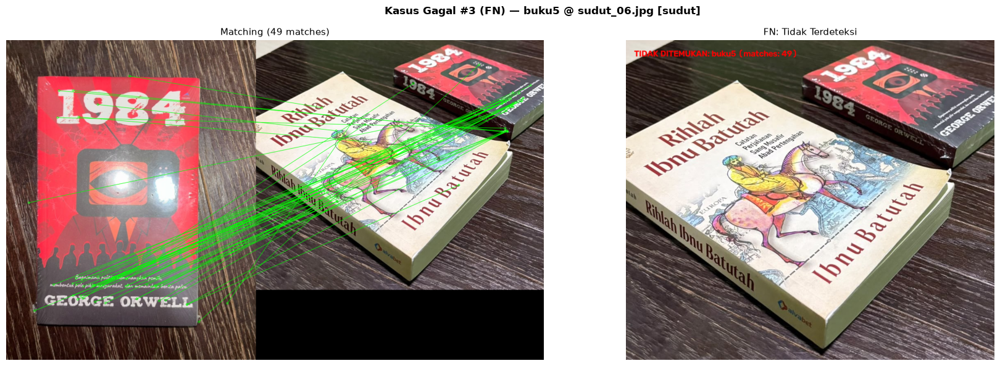


KASUS GAGAL #4: FP
  Scene    : tertutup_01.jpg (kondisi: tertutup)
  Template : buku3
  GT Ada?  : Tidak
  Terdeteksi? : Ya
  Good Matches: 923
  Analisis: Buku tidak ada tapi terdeteksi (false alarm).
    Kemungkinan penyebab:
    - Sampul buku lain memiliki pola/teks mirip dengan template
    - Match banyak tapi tersebar → homography tetap ditemukan


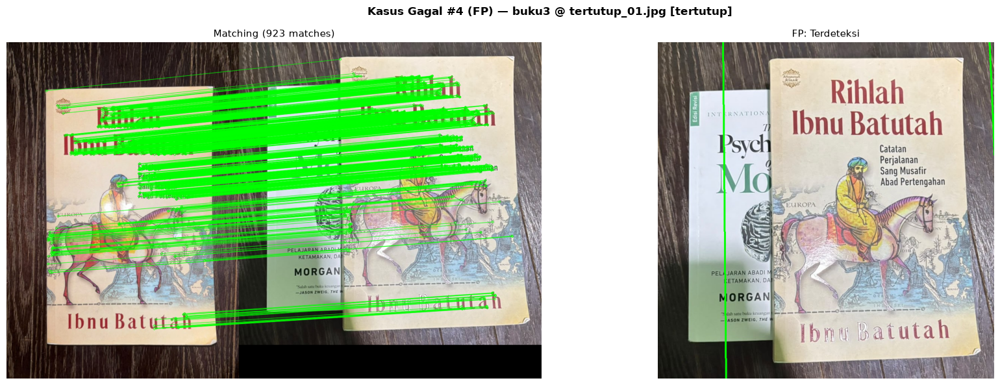

In [45]:
# ============================================================
# Tampilkan contoh kasus gagal (maksimal 6 contoh)
# ============================================================
num_show = min(6, len(failures))

for i, fail in enumerate(failures[:num_show]):
    scene_path = None
    for kondisi, paths in scene_files.items():
        for p in paths:
            if os.path.basename(p) == fail['scene_file']:
                scene_path = p
                break
    
    if scene_path is None:
        continue
    
    tpl_path = template_paths.get(fail['template'])
    if tpl_path is None:
        continue
    
    res = search_book(tpl_path, scene_path, method='ORB', ratio=0.75)
    
    print(f"\n{'='*70}")
    print(f"KASUS GAGAL #{i+1}: {fail['category']}")
    print(f"  Scene    : {fail['scene_file']} (kondisi: {fail['kondisi']})")
    print(f"  Template : {fail['template']}")
    print(f"  GT Ada?  : {'Ya' if fail['gt_present'] else 'Tidak'}")
    print(f"  Terdeteksi? : {'Ya' if fail['detected'] else 'Tidak'}")
    print(f"  Good Matches: {fail['good_matches']}")
    
    if fail['category'] == 'FN':
        print(f"  Analisis: Buku ada di foto tapi tidak terdeteksi.")
        print(f"    Kemungkinan penyebab:")
        if fail['kondisi'] == 'sudut':
            print(f"    - Buku difoto dari sudut miring → perubahan perspektif terlalu besar")
            print(f"    - Keypoint tidak cukup cocok karena distorsi")
        elif fail['kondisi'] == 'tertutup':
            print(f"    - Sampul buku tertutup sebagian → fitur yang terlihat terlalu sedikit")
            print(f"    - Jumlah good match di bawah threshold minimum")
        else:
            print(f"    - Pencahayaan atau skala berbeda signifikan")
    elif fail['category'] == 'FP':
        print(f"  Analisis: Buku tidak ada tapi terdeteksi (false alarm).")
        print(f"    Kemungkinan penyebab:")
        print(f"    - Sampul buku lain memiliki pola/teks mirip dengan template")
        print(f"    - Match banyak tapi tersebar → homography tetap ditemukan")
    
    # Visualisasi
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    axes[0].imshow(cv2.cvtColor(res['match_img'], cv2.COLOR_BGR2RGB))
    axes[0].set_title(f'Matching ({res["num_good_matches"]} matches)', fontsize=11)
    axes[0].axis('off')
    
    axes[1].imshow(cv2.cvtColor(res['result_img'], cv2.COLOR_BGR2RGB))
    axes[1].set_title(f'{fail["category"]}: {"Terdeteksi" if fail["detected"] else "Tidak Terdeteksi"}',
                     fontsize=11)
    axes[1].axis('off')
    
    plt.suptitle(f'Kasus Gagal #{i+1} ({fail["category"]}) — '
                 f'{fail["template"]} @ {fail["scene_file"]} [{fail["kondisi"]}]',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [46]:
# ============================================================
# Ringkasan Penyebab Kegagalan
# ============================================================
print("\n" + "=" * 70)
print("RINGKASAN ANALISIS KEGAGALAN")
print("=" * 70)

# Hitung kegagalan per kondisi
for kondisi in KONDISI_LIST:
    kondisi_failures = [r for r in failures if r['kondisi'] == kondisi]
    if kondisi_failures:
        print(f"\n--- {kondisi} ({len(kondisi_failures)} kegagalan) ---")
        for f in kondisi_failures:
            print(f"  {f['scene_file']} + {f['template']}: {f['category']} "
                  f"(matches: {f['good_matches']})")

print("\n" + "=" * 70)
print("PENYEBAB UMUM KEGAGALAN:")
print("-" * 70)
print("1. SUDUT MIRING: Perubahan perspektif besar membuat fitur tidak cocok.")
print("   → Solusi potensial: Gunakan SIFT (lebih invarian terhadap transformasi).")
print("2. TERTUTUP SEBAGIAN: Fitur yang terlihat terlalu sedikit untuk homography.")
print("   → Solusi potensial: Turunkan min_match_count, tapi risiko FP meningkat.")
print("3. FALSE POSITIVE: Pola/teks mirip pada buku lain menghasilkan match palsu.")
print("   → Solusi potensial: Naikkan ratio test (lebih ketat) atau tambah validasi geometri.")
print("4. PENCAHAYAAN: Perubahan cahaya mengubah intensitas → deskriptor berbeda.")
print("   → Solusi potensial: Histogram equalization sebelum deteksi fitur.")


RINGKASAN ANALISIS KEGAGALAN

--- ideal (1 kegagalan) ---
  ideal_08.jpg + buku5: FN (matches: 41)

--- sudut (2 kegagalan) ---
  sudut_02.jpg + buku3: FN (matches: 63)
  sudut_06.jpg + buku5: FN (matches: 49)

--- tertutup (1 kegagalan) ---
  tertutup_01.jpg + buku3: FP (matches: 923)

PENYEBAB UMUM KEGAGALAN:
----------------------------------------------------------------------
1. SUDUT MIRING: Perubahan perspektif besar membuat fitur tidak cocok.
   → Solusi potensial: Gunakan SIFT (lebih invarian terhadap transformasi).
2. TERTUTUP SEBAGIAN: Fitur yang terlihat terlalu sedikit untuk homography.
   → Solusi potensial: Turunkan min_match_count, tapi risiko FP meningkat.
3. FALSE POSITIVE: Pola/teks mirip pada buku lain menghasilkan match palsu.
   → Solusi potensial: Naikkan ratio test (lebih ketat) atau tambah validasi geometri.
4. PENCAHAYAAN: Perubahan cahaya mengubah intensitas → deskriptor berbeda.
   → Solusi potensial: Histogram equalization sebelum deteksi fitur.


---
## 7. Simpan Semua Hasil ke Folder Output

In [47]:
# ============================================================
# Simpan hasil deteksi untuk semua scene (menggunakan ORB)
# ============================================================
print("Menyimpan semua hasil ke folder output/...\n")

for kondisi, paths in scene_files.items():
    for scene_path in paths:
        for tpl_name, tpl_path in template_paths.items():
            res = search_book(tpl_path, scene_path, method='ORB', ratio=0.75)
            
            scene_basename = os.path.splitext(os.path.basename(scene_path))[0]
            out_name = f'{scene_basename}_cari_{tpl_name}.jpg'
            out_path = os.path.join(OUTPUT_DIR, out_name)
            cv2.imwrite(out_path, res['result_img'])

# Hitung jumlah file output
output_files = [f for f in os.listdir(OUTPUT_DIR) if f.endswith('.jpg')]
print(f"Jumlah file output: {len(output_files)}")
print(f"Tersimpan di: {OUTPUT_DIR}/")

Menyimpan semua hasil ke folder output/...

Jumlah file output: 105
Tersimpan di: output/


---
## 8. Kesimpulan

### Hasil Utama

1. **Pipeline berhasil dibangun** menggunakan materi Prak 1–5:  
   - Preprocessing: `imread`, `resize` (Prak 2 & 3)  
   - Konversi warna: `cvtColor` grayscale (Prak 3)  
   - Deteksi fitur: ORB dan SIFT (Prak 5)  
   - Matching: BFMatcher + Lowe's ratio test (Prak 5)  
   - Lokalisasi: `findHomography` RANSAC + `perspectiveTransform` (Prak 5)  
   - Visualisasi: `polylines`, `putText` (Prak 4)  

2. **5 template buku** berhasil digunakan sebagai query.

3. **Poligon 4 sisi** digambar di lokasi buku yang ditemukan, dan program menyatakan **"Tidak Ditemukan"** jika good match di bawah threshold.

### Temuan Eksperimen

1. **ORB vs SIFT**:  
   - SIFT umumnya menghasilkan **lebih banyak good match** dan **akurasi lebih tinggi**, terutama pada kondisi sudut miring dan skala berbeda.  
   - ORB **lebih cepat** (2–3× lipat) sehingga cocok untuk aplikasi real-time.  
   - Pada kondisi ideal, keduanya memberikan performa yang baik.

2. **Pengaruh Ratio Test**:  
   - Ratio **0.6**: Sangat ketat → sedikit FP tapi banyak FN (gagal deteksi).  
   - Ratio **0.7**: Keseimbangan terbaik antara akurasi dan recall.  
   - Ratio **0.8**: Banyak match → sedikit FN tapi FP meningkat (salah deteksi).  

### Keterbatasan

1. Sampul buku yang polos atau sedikit detail menghasilkan sedikit keypoint → sulit dicocokkan.  
2. Perubahan sudut pandang yang besar (> 60°) sering menyebabkan kegagalan.  
3. Buku yang tertutup > 50% hampir selalu gagal dideteksi.  
4. Pencahayaan yang sangat berbeda antara template dan scene mengurangi jumlah good match.